In [1]:
# Core libraries
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Machine-learning tools
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    learning_curve,
)

In [2]:
# Assemble the purity-classification dataset from
# trimmed pure-AA and mixture recordings.

# DATA_DIR = Path(".")
DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

PURE_SUB_EVENT_DIR = (
    DATA_DIR / "trim_sub_events_g_CD"
)

PURE_EVENT_DIR = (
    DATA_DIR / "trim_events_g_CD"
)

PURE_BASELINE_DIR = (
    DATA_DIR / "final_baseline_info_g_CD"
)

MIXTURE_SUB_EVENT_DIR = (
    DATA_DIR / "trim_sub_events_g_CD_mix"
)

MIXTURE_EVENT_DIR = (
    DATA_DIR / "trim_events_g_CD_mix"
)

MIXTURE_BASELINE_DIR = (
    DATA_DIR / "final_baseline_info_g_CD_mix"
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def assemble_purity_data(
    sub_event_dir,
    event_dir,
    baseline_dir,
    purity_label,
):
    """Match secondary events to their parent first-level events."""

    assembled_recordings = []

    for sub_event_file in sorted(
        sub_event_dir.glob("*.csv")
    ):
        recording_id = (
            sub_event_file.stem.removesuffix("_sub")
        )

        event_file = (
            event_dir
            / f"{recording_id}.csv"
        )

        baseline_file = (
            baseline_dir
            / f"{recording_id}_final.csv"
        )

        if not event_file.exists():
            raise FileNotFoundError(
                f"Missing event file: "
                f"{event_file.name}"
            )

        if not baseline_file.exists():
            raise FileNotFoundError(
                f"Missing baseline file: "
                f"{baseline_file.name}"
            )

        sub_events = pd.read_csv(
            sub_event_file
        )

        first_level_events = pd.read_csv(
            event_file
        )

        baseline_data = pd.read_csv(
            baseline_file
        )

        if baseline_data.empty:
            raise ValueError(
                f"Baseline file is empty: "
                f"{baseline_file.name}"
            )

        open_pore_rms = (
            baseline_data["rms"].iloc[0]
        )

        matched_rows = []

        for _, sub_event in sub_events.iterrows():
            parent_event = first_level_events.loc[
                (
                    first_level_events["start_time_s"]
                    <= sub_event["sub_start_time_s"]
                )
                & (
                    first_level_events["end_time_s"]
                    >= sub_event["sub_end_time_s"]
                )
            ]

            if parent_event.empty:
                continue

            parent_event = parent_event.iloc[0]

            event_id = (
                f"{recording_id}_"
                f"{int(parent_event['event_index'])}"
            )

            matched_rows.append({
                "sub_pre_interaction_current":
                    sub_event[
                        "sub_pre_interaction_current"
                    ],

                "sub_post_interaction_current":
                    sub_event[
                        "sub_post_interaction_current"
                    ],

                # I1
                "first_level_current":
                    sub_event["sub_mode_baseline"],

                # σ1
                "first_level_stdev":
                    parent_event["blockage_stdev"],

                # σ0
                "open_pore_rms":
                    open_pore_rms,

                "dwell_time_us":
                    parent_event["dwell_time_us"],

                "num_sub_events":
                    parent_event["num_sub_events"],

                # Parent first-level blockage
                "event_id":
                    event_id,

                # Single-pore recording
                "dataset_id":
                    recording_id,

                "sample_id":
                    (
                        recording_id[:2]
                        if purity_label == "Mixture"
                        else recording_id[0]
                    ),

                "purity":
                    purity_label,
            })

        if matched_rows:
            assembled_recordings.append(
                pd.DataFrame(matched_rows)
            )

    if not assembled_recordings:
        raise ValueError(
            f"No matched observations found in "
            f"{sub_event_dir}"
        )

    return pd.concat(
        assembled_recordings,
        ignore_index=True,
    )


pure_data = assemble_purity_data(
    sub_event_dir=PURE_SUB_EVENT_DIR,
    event_dir=PURE_EVENT_DIR,
    baseline_dir=PURE_BASELINE_DIR,
    purity_label="Pure",
)

mixture_data = assemble_purity_data(
    sub_event_dir=MIXTURE_SUB_EVENT_DIR,
    event_dir=MIXTURE_EVENT_DIR,
    baseline_dir=MIXTURE_BASELINE_DIR,
    purity_label="Mixture",
)

# Exclude the underivatized ADIC control.
pure_data = (
    pure_data.loc[
        pure_data["sample_id"] != "0"
    ]
    .reset_index(drop=True)
)

df = pd.concat(
    [
        pure_data,
        mixture_data,
    ],
    ignore_index=True,
)

if df.isna().any().any():
    missing_columns = (
        df.columns[
            df.isna().any()
        ]
        .tolist()
    )

    raise ValueError(
        f"Missing values detected in: "
        f"{missing_columns}"
    )

if (df["open_pore_rms"] <= 0).any():
    raise ValueError(
        "All open-pore RMS values must be positive."
    )

print(
    f"Purity classes: "
    f"{df['purity'].nunique()}"
)

print(
    f"Secondary events: "
    f"{len(df):,}"
)

print(
    f"First-level events: "
    f"{df['event_id'].nunique():,}"
)

print(
    f"Single-pore recordings: "
    f"{df['dataset_id'].nunique():,}"
)

print(
    "\nObservations by class:"
)

print(
    df["purity"].value_counts()
)

display(df.head())

Purity classes: 2
Secondary events: 205,729
First-level events: 15,402
Single-pore recordings: 311

Observations by class:
purity
Pure       110862
Mixture     94867
Name: count, dtype: int64


,sub_pre_interaction_current,sub_post_interaction_current,first_level_current,first_level_stdev,open_pore_rms,dwell_time_us,num_sub_events,event_id,dataset_id,sample_id,purity
0,102.386470,114.440910,126.70898,24.660622,2.35353,17710.0,5.0,A_g_CD_250528__0002_0,A_g_CD_250528__0002,A,Pure
1,114.379875,110.829660,126.70898,24.660622,2.35353,17710.0,5.0,A_g_CD_250528__0002_0,A_g_CD_250528__0002,A,Pure
2,104.125970,112.121574,126.70898,24.660622,2.35353,17710.0,5.0,A_g_CD_250528__0002_0,A_g_CD_250528__0002,A,Pure
3,105.438225,111.724846,126.70898,24.660622,2.35353,17710.0,5.0,A_g_CD_250528__0002_0,A_g_CD_250528__0002,A,Pure
4,103.820790,111.206050,126.70898,24.660622,2.35353,17710.0,5.0,A_g_CD_250528__0002_0,A_g_CD_250528__0002,A,Pure


In [3]:
# Split by parent first-level blockage and construct
# the four classifier features.

FEATURE_NAMES = [
    "Baseline Ratio",
    "Z Score",
    "Per-event Impact",
    "Per-time Impact",
]

# Preserve the original purity encoding.
PURITY_ENCODING = {
    "Pure": 0,
    "Mixture": 1,
}

PURITY_DECODING = {
    encoded_label: class_name
    for class_name, encoded_label
    in PURITY_ENCODING.items()
}

print(
    "Purity mapping:",
    PURITY_ENCODING,
)

event_table = (
    df[
        [
            "event_id",
            "dataset_id",
            "purity",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "purity",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)

# Confirm that every event_id represents exactly one
# parent first-level blockage and one purity class.
event_validation = (
    df.groupby("event_id")
    .agg(
        purity_count=(
            "purity",
            "nunique",
        ),
        dataset_count=(
            "dataset_id",
            "nunique",
        ),
    )
)

if (
    (
        event_validation["purity_count"]
        != 1
    ).any()
    or (
        event_validation["dataset_count"]
        != 1
    ).any()
):
    raise ValueError(
        "Each event_id must correspond to one purity "
        "class and one single-pore recording."
    )

# Deterministic 60:20:20 target split within each class.
rng = np.random.default_rng(42)
split_assignment = {}

for purity_class in [
    "Pure",
    "Mixture",
]:
    class_event_ids = (
        event_table.loc[
            event_table["purity"]
            == purity_class,
            "event_id",
        ]
        .sort_values()
        .to_numpy()
    )

    class_event_ids = rng.permutation(
        class_event_ids
    )

    number_of_events = len(
        class_event_ids
    )

    number_train = max(
        1,
        int(
            np.floor(
                0.60 * number_of_events
            )
        ),
    )

    number_validation = max(
        1,
        int(
            np.floor(
                0.20 * number_of_events
            )
        ),
    )

    if (
        number_train
        + number_validation
        >= number_of_events
    ):
        number_validation = max(
            0,
            number_of_events
            - number_train
            - 1,
        )

    train_event_ids = (
        class_event_ids[:number_train]
    )

    validation_event_ids = (
        class_event_ids[
            number_train:
            number_train + number_validation
        ]
    )

    test_event_ids = (
        class_event_ids[
            number_train
            + number_validation:
        ]
    )

    for event_id in train_event_ids:
        split_assignment[event_id] = "train"

    for event_id in validation_event_ids:
        split_assignment[event_id] = "validation"

    for event_id in test_event_ids:
        split_assignment[event_id] = "test"

# Every recording must contribute training events because
# recording-level features are calculated from training
# observations only.
for dataset_id in sorted(
    event_table["dataset_id"].unique()
):
    recording_event_ids = (
        event_table.loc[
            event_table["dataset_id"]
            == dataset_id,
            "event_id",
        ]
        .sort_values()
        .tolist()
    )

    has_training_event = any(
        split_assignment[event_id]
        == "train"
        for event_id in recording_event_ids
    )

    if not has_training_event:
        event_to_move = recording_event_ids[0]

        split_assignment[
            event_to_move
        ] = "train"

df["split"] = df["event_id"].map(
    split_assignment
)

if df["split"].isna().any():
    raise ValueError(
        "Some observations were not assigned "
        "to a split."
    )

train_mask = df["split"] == "train"
validation_mask = (
    df["split"] == "validation"
)
test_mask = df["split"] == "test"

# Calculate recording-level aggregate values using
# training observations only.
training_rows = df.loc[
    train_mask
].copy()

training_secondary_event_count = (
    training_rows
    .groupby("dataset_id")
    .size()
    .rename(
        "training_secondary_event_count"
    )
)

training_first_level_dwell_time = (
    training_rows[
        [
            "dataset_id",
            "event_id",
            "dwell_time_us",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .groupby("dataset_id")[
        "dwell_time_us"
    ]
    .sum()
    .rename(
        "training_first_level_dwell_time"
    )
)

training_aggregates = pd.concat(
    [
        training_secondary_event_count,
        training_first_level_dwell_time,
    ],
    axis=1,
)

training_aggregates[
    "training_event_frequency"
] = (
    training_aggregates[
        "training_secondary_event_count"
    ]
    / training_aggregates[
        "training_first_level_dwell_time"
    ]
)

if (
    training_aggregates.isna().any().any()
    or (
        training_aggregates[
            "training_secondary_event_count"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_first_level_dwell_time"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_event_frequency"
        ]
        <= 0
    ).any()
):
    raise ValueError(
        "Invalid training-derived aggregate values "
        "detected."
    )

feature_source = df.copy()

for aggregate_column in [
    "training_secondary_event_count",
    "training_first_level_dwell_time",
    "training_event_frequency",
]:
    feature_source[
        aggregate_column
    ] = feature_source["dataset_id"].map(
        training_aggregates[
            aggregate_column
        ]
    )

aggregate_columns = [
    "training_secondary_event_count",
    "training_first_level_dwell_time",
    "training_event_frequency",
]

if (
    feature_source[
        aggregate_columns
    ]
    .isna()
    .any()
    .any()
):
    missing_recordings = (
        feature_source.loc[
            feature_source[
                aggregate_columns
            ]
            .isna()
            .any(axis=1),
            "dataset_id",
        ]
        .unique()
        .tolist()
    )

    raise ValueError(
        "No training-derived aggregate values for: "
        f"{missing_recordings}"
    )

# Construct the four classifier features.
feature_source["Baseline Ratio"] = (
    feature_source[
        "sub_post_interaction_current"
    ]
    / feature_source[
        "first_level_current"
    ]
)

# Z score normalized by open-pore noise σ0.
feature_source["Z Score"] = (
    (
        feature_source[
            "sub_post_interaction_current"
        ]
        - feature_source[
            "first_level_current"
        ]
    )
    / feature_source[
        "open_pore_rms"
    ]
)

feature_source["Per-event Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_secondary_event_count"
    ]
)

feature_source["Per-time Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_event_frequency"
    ]
)

if not np.isfinite(
    feature_source[
        FEATURE_NAMES
    ].to_numpy()
).all():
    raise ValueError(
        "Nonfinite values detected in "
        "classifier features."
    )

X_train = (
    feature_source.loc[
        train_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

X_val = (
    feature_source.loc[
        validation_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

X_test = (
    feature_source.loc[
        test_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    feature_source.loc[
        train_mask,
        "purity",
    ]
    .map(PURITY_ENCODING)
    .to_numpy()
)

y_val = (
    feature_source.loc[
        validation_mask,
        "purity",
    ]
    .map(PURITY_ENCODING)
    .to_numpy()
)

y_test = (
    feature_source.loc[
        test_mask,
        "purity",
    ]
    .map(PURITY_ENCODING)
    .to_numpy()
)

groups_train = (
    feature_source.loc[
        train_mask,
        "event_id",
    ]
    .reset_index(drop=True)
    .to_numpy()
)

split_assignment_df = (
    feature_source[
        [
            "event_id",
            "dataset_id",
            "purity",
            "split",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "purity",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)

split_assignment_df.to_csv(
    OUTPUT_DIR
    / "purity_classifier_split_assignment.csv",
    index=False,
)

joblib.dump(
    PURITY_ENCODING,
    OUTPUT_DIR
    / "purity_classifier_label_mapping.joblib",
)

print(
    f"Training observations: "
    f"{len(X_train):,}"
)

print(
    f"Validation observations: "
    f"{len(X_val):,}"
)

print(
    f"Test observations: "
    f"{len(X_test):,}"
)

print(
    "\nParent first-level events by split:"
)

print(
    split_assignment_df["split"]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ],
        fill_value=0,
    )
)

Purity mapping: {'Pure': 0, 'Mixture': 1}
Training observations: 122,991
Validation observations: 42,549
Test observations: 40,189

Parent first-level events by split:
split
train         9243
validation    3080
test          3079
Name: count, dtype: int64


In [4]:
# Train the purity random forest classifier.

purity_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1,
)

purity_classifier.fit(
    X_train,
    y_train,
)

MODEL_PATH = (
    OUTPUT_DIR
    / "purity_classifier.joblib"
)

joblib.dump(
    purity_classifier,
    MODEL_PATH,
)

print(
    f"Model saved to: "
    f"{MODEL_PATH.resolve()}"
)

Model saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/purity_classifier.joblib


In [5]:
# Evaluate the purity classifier.

grouped_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_scores = cross_val_score(
    clone(purity_classifier),
    X_train,
    y_train,
    groups=groups_train,
    cv=grouped_cv,
    scoring="accuracy",
    n_jobs=-1,
)

y_test_pred = purity_classifier.predict(
    X_test
)

y_test_proba = (
    purity_classifier.predict_proba(
        X_test
    )[:, 1]
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred,
)

validation_accuracy = (
    purity_classifier.score(
        X_val,
        y_val,
    )
)

f1_micro = f1_score(
    y_test,
    y_test_pred,
    average="micro",
)

f1_macro = f1_score(
    y_test,
    y_test_pred,
    average="macro",
)

precision_micro = precision_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

recall_micro = recall_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

auc_score = roc_auc_score(
    y_test,
    y_test_proba,
)

metrics_summary = pd.DataFrame({
    "metric": [
        "test_accuracy",
        "validation_accuracy",
        "cross_validation_mean",
        "cross_validation_std",
        "f1_micro",
        "f1_macro",
        "precision_micro",
        "recall_micro",
        "auc",
    ],
    "value": [
        test_accuracy,
        validation_accuracy,
        cv_scores.mean(),
        cv_scores.std(),
        f1_micro,
        f1_macro,
        precision_micro,
        recall_micro,
        auc_score,
    ],
})

cv_results = pd.DataFrame({
    "fold": np.arange(
        1,
        len(cv_scores) + 1,
    ),
    "accuracy": cv_scores,
})

test_predictions = pd.DataFrame({
    "actual_encoded": y_test,
    "predicted_encoded": y_test_pred,
    "mixture_probability": y_test_proba,
})

test_predictions["actual"] = (
    test_predictions[
        "actual_encoded"
    ].map(PURITY_DECODING)
)

test_predictions["predicted"] = (
    test_predictions[
        "predicted_encoded"
    ].map(PURITY_DECODING)
)

metrics_summary.to_csv(
    OUTPUT_DIR
    / "purity_classifier_metrics.csv",
    index=False,
)

cv_results.to_csv(
    OUTPUT_DIR
    / "purity_classifier_cross_validation.csv",
    index=False,
)

test_predictions.to_csv(
    OUTPUT_DIR
    / "purity_classifier_test_predictions.csv",
    index=False,
)

display(metrics_summary)
display(cv_results)

,metric,value
0,test_accuracy,0.994874
1,validation_accuracy,0.986580
2,cross_validation_mean,0.993872
3,cross_validation_std,0.002732
4,f1_micro,0.994874
5,f1_macro,0.994835
6,precision_micro,0.994874
7,recall_micro,0.994874
8,auc,0.999691


,fold,accuracy
0,1,0.995753
1,2,0.995490
2,3,0.995582
3,4,0.988559
4,5,0.993977


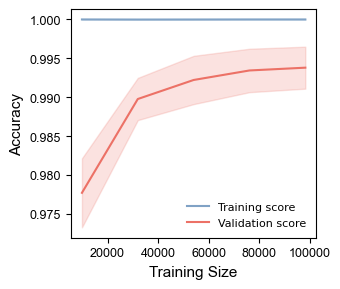

In [6]:
# Plot the grouped learning curve.

train_sizes, train_scores, validation_scores = (
    learning_curve(
        estimator=clone(purity_classifier),
        X=X_train,
        y=y_train,
        groups=groups_train,
        cv=grouped_cv,
        train_sizes=np.linspace(
            0.1,
            1.0,
            5,
        ),
        scoring="accuracy",
        shuffle=True,
        random_state=42,
        n_jobs=-1,
    )
)

training_mean = train_scores.mean(axis=1)
training_std = train_scores.std(axis=1)

validation_mean = (
    validation_scores.mean(axis=1)
)

validation_std = (
    validation_scores.std(axis=1)
)

learning_curve_data = pd.DataFrame({
    "training_size": train_sizes,
    "training_accuracy_mean": training_mean,
    "training_accuracy_std": training_std,
    "validation_accuracy_mean": validation_mean,
    "validation_accuracy_std": validation_std,
})

learning_curve_data.to_csv(
    OUTPUT_DIR
    / "purity_classifier_learning_curve.csv",
    index=False,
)

plt.figure(figsize=(3.5, 3))

plt.plot(
    train_sizes,
    training_mean,
    color="#80A2C5",
    linewidth=1.5,
    label="Training score",
)

plt.fill_between(
    train_sizes,
    training_mean - training_std,
    training_mean + training_std,
    color="#80A2C5",
    alpha=0.20,
)

plt.plot(
    train_sizes,
    validation_mean,
    color="#EC7166",
    linewidth=1.5,
    label="Validation score",
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    color="#EC7166",
    alpha=0.20,
)

plt.xlabel(
    "Training Size",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Accuracy",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.legend(
    fontsize=8,
    frameon=False,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "purity_classifier_learning_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

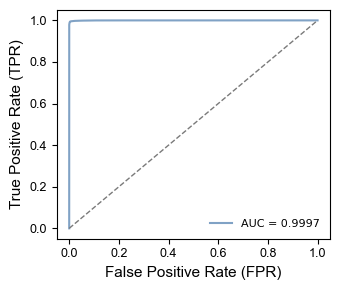

In [7]:
# Plot the binary ROC curve.

false_positive_rate, true_positive_rate, _ = (
    roc_curve(
        y_test,
        y_test_proba,
        pos_label=1,
    )
)

roc_auc = auc(
    false_positive_rate,
    true_positive_rate,
)

roc_curve_data = pd.DataFrame({
    "false_positive_rate":
        false_positive_rate,

    "true_positive_rate":
        true_positive_rate,
})

roc_curve_data.to_csv(
    OUTPUT_DIR
    / "purity_classifier_ROC_curve.csv",
    index=False,
)

plt.figure(figsize=(3.5, 3))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="#80A2C5",
    linewidth=1.5,
    label=f"AUC = {roc_auc:.4f}",
)

plt.plot(
    [0, 1],
    [0, 1],
    color="#7A7A7A",
    linestyle="--",
    linewidth=1,
)

plt.xlabel(
    "False Positive Rate (FPR)",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "True Positive Rate (TPR)",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.legend(
    loc="lower right",
    fontsize=8,
    frameon=False,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "purity_classifier_ROC_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

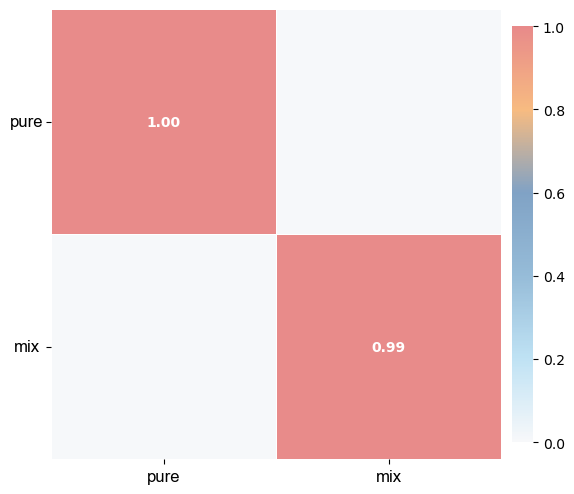

In [9]:
destination_folder = str(OUTPUT_DIR)
from matplotlib.colors import LinearSegmentedColormap

custom_order = ['0', '1']

custom_order_encoded = [0, 1]

confusion_mtx = confusion_matrix(
    y_test, y_test_pred, labels=custom_order_encoded
)
confusion_mtx_normalized = confusion_mtx.astype(float) / confusion_mtx.sum(axis=1)[:, np.newaxis]


plot_mtx = confusion_mtx_normalized.T
annot_mtx = np.empty_like(plot_mtx, dtype=object)
annot_mtx[:] = ""
for i in range(plot_mtx.shape[0]):
    annot_mtx[i, i] = f"{plot_mtx[i, i]:.2f}"

paper_warm = LinearSegmentedColormap.from_list(
    "paper_warm",
    ["#F7F8FA", "#BFE2F4", "#96BCD8", "#80A2C5", "#F7BB81", "#E88A8A"],
    N=256
)   

purity_index = ["pure", "mix"]
plt.figure(figsize=(7, 6))
ax = sns.heatmap(plot_mtx,
    annot=annot_mtx,
    fmt="",
    cmap=paper_warm,      
    vmin=0,
    vmax=1,
    xticklabels=purity_index,
    yticklabels=purity_index,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar=True,
    annot_kws={"size": 10, "weight": "bold", "color": "white"},
    cbar_kws={"shrink": 0.9, "pad": 0.02})
#plt.xlabel("Predicted Amino Acid", fontsize=15, fontfamily='Arial', fontweight='bold')
#plt.ylabel("Actual Amino Acid", fontsize=15, fontfamily='Arial', fontweight='bold')
#plt.title("Confusion Matrix", fontsize=24, fontfamily='Arial', fontweight='bold')
ax.tick_params(axis='y', pad=14) 
for label in ax.get_yticklabels():
    label.set_verticalalignment('center')
    label.set_horizontalalignment('center')  
plt.xticks(rotation=0, fontsize=12, fontfamily='Arial')   
plt.yticks(rotation=0, va="center", fontsize=12, fontfamily='Arial')  

output_filename = f'final_sup_fig_19e.png'
output_path = OUTPUT_DIR / output_filename
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

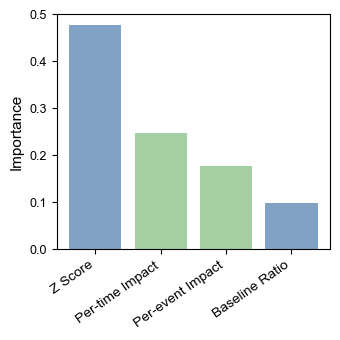

In [10]:
# Plot feature importance for the purity classifier.

feature_importance_data = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Importance":
        purity_classifier.feature_importances_,
})

feature_category = {
    "Baseline Ratio": "Local",
    "Z Score": "Local",
    "Per-event Impact": "Global",
    "Per-time Impact": "Global",
}

feature_importance_data["Category"] = (
    feature_importance_data["Feature"]
    .map(feature_category)
)

feature_importance_data = (
    feature_importance_data
    .sort_values(
        "Importance",
        ascending=False,
    )
    .reset_index(drop=True)
)

feature_importance_data.to_csv(
    OUTPUT_DIR
    / "purity_classifier_feature_importance.csv",
    index=False,
)

LOCAL_COLOR = "#80A2C5"
GLOBAL_COLOR = "#A3CFA2"

bar_colors = (
    feature_importance_data["Category"]
    .map({
        "Local": LOCAL_COLOR,
        "Global": GLOBAL_COLOR,
    })
    .tolist()
)

plt.figure(figsize=(3.5, 3.5))

plt.bar(
    feature_importance_data["Feature"],
    feature_importance_data["Importance"],
    color=bar_colors,
    edgecolor="none",
)

plt.xlabel("")

plt.ylabel(
    "Importance",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

ax = plt.gca()
ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "purity_classifier_feature_importance.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()